# Exploração dos dados — Olist

**Tech Challenge · Fase 1** · Estudo de caso para investidores do setor de e-commerce

Este notebook é a primeira interação e observação dos dados. O objetivo é entender o que a base da Olist contém, onde estão os problemas de qualidade.

**Pergunta do estudo:** Onde a Olist deve priorizar seus próximos investimentos para sustentar o crescimento da receita?

**Perguntas norteadoras:**

- P1. Como a receita evoluiu e onde ela está concentrada?
- P2. Quanto o atraso na entrega pesa na satisfação do cliente?
- P3. Os clientes voltam a comprar?

**Método (KDD).** Este notebook cobre as duas primeiras etapas: **seleção** (quais dados temos) e **pré-processamento** (diagnóstico da qualidade). O tratamento em si é feito no script `src/transformacoes.py`, e as análises finais, no Power BI.

## 0. Preparação do ambiente

Bibliotecas e caminhos.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

# Raiz do repositório
RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DIR_RAW = RAIZ / "data" / "raw"
DIR_FIG = RAIZ / "reports" / "figuras"
DIR_FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

print(f"Lendo os dados de: {DIR_RAW}")

Lendo os dados de: c:\Users\vgome\Documents\Estudos\Escolas\FIAP (Pós)\Conteúdo\Fase 1\Tech Challenge\Projeto\data\raw


## 1. Seleção: quais dados temos

A base tem 9 arquivos. A tabela de geolocalização fica **fora do escopo** pois não é necessária para as perguntas do estudo.

### 1.1 Carregando as tabelas

Duas observações na leitura dos arquivos:
- os CEPs são lidos como texto, para não perder o zero à esquerda (o CEP `01151` viraria `1151`);
- o `encoding="utf-8-sig"` remove um caractere invisível que vem no cabeçalho de um dos arquivos.

In [2]:
arquivos = {
    "orders": "olist_orders_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "products": "olist_products_dataset.csv",
    "traducao": "product_category_name_translation.csv",
}
cep_como_texto = {"customer_zip_code_prefix": str, "seller_zip_code_prefix": str}

dados = {
    nome: pd.read_csv(DIR_RAW / arquivo, encoding="utf-8-sig", dtype=cep_como_texto)
    for nome, arquivo in arquivos.items()
}

orders, items, payments, reviews = dados["orders"], dados["items"], dados["payments"], dados["reviews"]
customers, sellers, products, traducao = dados["customers"], dados["sellers"], dados["products"], dados["traducao"]

### 1.2 Tamanho de cada tabela

In [3]:
pd.DataFrame({
    "linhas": {nome: len(tabela) for nome, tabela in dados.items()},
    "colunas": {nome: tabela.shape[1] for nome, tabela in dados.items()},
})

,linhas,colunas
orders,99441,8
items,112650,7
payments,103886,5
reviews,99224,7
customers,99441,5
sellers,3095,4
products,32951,9
traducao,71,2


**Anotações:** 
- A quantidade de compras (orders) é igual a quantidade de linhas em clientes (customers), logo cada pedido gera um id de cliente.
- A quantidade de linhas em itens de compra é maior pelo fato de cada compra poder ter mais de um item.

### 1.3 Tabela principal: Pedidos

A tabela `orders` é a principal do modelo: todas as outras se ligam a ela. As datas vêm como texto e precisam ser convertidas para que dê para calcular prazos.

In [4]:
colunas_data = [
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date",
]
orders[colunas_data] = orders[colunas_data].apply(pd.to_datetime)

orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [5]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 6.1 MB


> **Anotação** a data prometida (`order_estimated_delivery_date`) vem sempre às 00:00, enquanto a data de entrega tem hora. Por isso o atraso deve comparar **só as datas**.

## 2. Entendendo as chaves e os relacionamentos

### 2.1 As chaves identificam uma linha só?

In [6]:
chaves = {
    "orders": ["order_id"],
    "items": ["order_id", "order_item_id"],
    "payments": ["order_id", "payment_sequential"],
    "reviews": ["review_id"],
    "customers": ["customer_id"],
    "sellers": ["seller_id"],
    "products": ["product_id"],
}
pd.DataFrame([
    {"tabela": tabela, "chave": " + ".join(colunas), "linhas repetidas": dados[tabela].duplicated(colunas).sum()}
    for tabela, colunas in chaves.items()
])

,tabela,chave,linhas repetidas
0,orders,order_id,0
1,items,order_id + order_item_id,0
2,payments,order_id + payment_sequential,0
3,reviews,review_id,814
4,customers,customer_id,0
5,sellers,seller_id,0
6,products,product_id,0


> **Anotação:** Observei que a review_id não é única, sendo necessário algum tratamento.

### 2.2 Quem é o cliente?

A tabela de clientes tem duas identificações. O `customer_id` e o `customer_unique_id`.

In [7]:
print(f"customer_id distintos:        {customers['customer_id'].nunique():>8,}")
print(f"customer_unique_id distintos: {customers['customer_unique_id'].nunique():>8,}")

customer_id distintos:          99,441
customer_unique_id distintos:   96,096


> **Anotação:** Contar clientes pelo `customer_id` faria o número de clientes igualar o de pedidos, o cliente da análise é o `customer_unique_id` que é único.

### 2.3 Todo pedido tem itens, pagamento e avaliação?

In [8]:
pedidos_ids = orders["order_id"]
pd.Series({
    "pedidos sem itens": (~pedidos_ids.isin(items["order_id"])).sum(),
    "pedidos sem pagamento": (~pedidos_ids.isin(payments["order_id"])).sum(),
    "pedidos sem avaliação": (~pedidos_ids.isin(reviews["order_id"])).sum(),
    "categorias sem tradução": (~products["product_category_name"].dropna().isin(traducao["product_category_name"])).sum(),
}, name="quantidade").to_frame()

,quantidade
pedidos sem itens,775
pedidos sem pagamento,1
pedidos sem avaliação,768
categorias sem tradução,13


> **Anotação:** Existem pedidos sem itens e sem pagamento, possivelmente farei um tratamento, pois podem se tratar de pedidos cancelados ou indisponíveis.

## 3. Pré-processamento: qualidade dos dados

### 3.1 Valores nulos

In [9]:
nulos = []
for nome, tabela in dados.items():
    for coluna, qtd in tabela.isna().sum().items():
        if qtd > 0:
            nulos.append({"tabela": nome, "coluna": coluna, "nulos": qtd, "% nulos": 100 * qtd / len(tabela)})

pd.DataFrame(nulos)

,tabela,coluna,nulos,% nulos
0,orders,order_approved_at,160,0.16
1,orders,order_delivered_carrier_date,1783,1.79
2,orders,order_delivered_customer_date,2965,2.98
3,reviews,review_comment_title,87656,88.34
4,reviews,review_comment_message,58247,58.70
5,products,product_category_name,610,1.85
6,products,product_name_lenght,610,1.85
7,products,product_description_lenght,610,1.85
8,products,product_photos_qty,610,1.85
9,products,product_weight_g,2,0.01


### 3.2 Repetições e casos especiais

In [10]:
pd.Series({
    "pedidos com mais de uma avaliação": reviews["order_id"].duplicated().sum(),
    "pedidos com mais de uma linha de pagamento": payments["order_id"].duplicated().sum(),
    "pagamentos com 0 parcelas": (payments["payment_installments"] == 0).sum(),
    "pedidos entregues sem data de entrega": (
        (orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].isna()
    ).sum(),
}, name="quantidade").to_frame()

,quantidade
pedidos com mais de uma avaliação,551
pedidos com mais de uma linha de pagamento,4446
pagamentos com 0 parcelas,2
pedidos entregues sem data de entrega,8


> **Anotação:** É possível observar que existem pedidos parcelados devido a quantidade de linhas de pagamento, sendo necessário sumarizar esses pagamentos por pedido.

### 3.3 Status dos pedidos

In [11]:
status = orders["order_status"].value_counts().to_frame("pedidos")
status["%"] = 100 * status["pedidos"] / status["pedidos"].sum()
status

,pedidos,%
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


> **Anotação:** Pedidos cancelados e indisponíveis, na prática não geraram venda, ficarão fora da análise.

## 4. Período: quais meses entram na análise

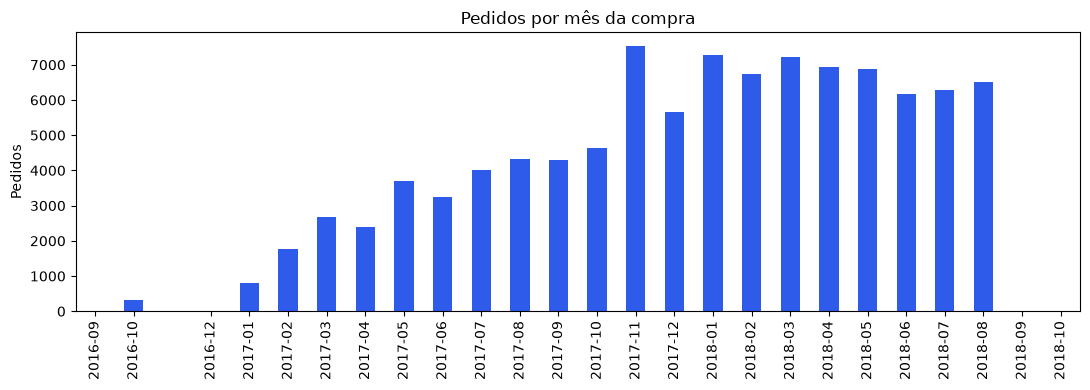

In [12]:
orders["ano_mes"] = orders["order_purchase_timestamp"].dt.to_period("M")
pedidos_por_mes = orders.groupby("ano_mes").size()

ax = pedidos_por_mes.plot(kind="bar", figsize=(11, 4), color="#2F5BEA", title="Pedidos por mês da compra")
ax.set_xlabel("")
ax.set_ylabel("Pedidos")
plt.tight_layout()
plt.savefig(DIR_FIG / "01_pedidos_por_mes.png", dpi=150)
plt.show()

In [13]:
# As pontas da série: primeiros e últimos meses
pd.concat([pedidos_por_mes.head(5), pedidos_por_mes.tail(4)]).to_frame("pedidos")

,pedidos
ano_mes,
2016-09,4
2016-10,324
2016-12,1
2017-01,800
2017-02,1780
2018-07,6292
2018-08,6512
2018-09,16
2018-10,4


## 5. Resumo da exploração

### Decisões levadas para o tratamento (`src/transformacoes.py`)

| Achado | Seção | Decisão no tratamento |
| --- | --- | --- |
| Meses incompletos no início e no fim da base | 4 | Recorte de jan/2017 a ago/2018 |
| Pedidos cancelados e indisponíveis | 3.3 | Excluídos da análise |
| `customer_id` muda a cada pedido | 2.2 | Cliente = `customer_unique_id` |
| Pedidos com mais de uma avaliação | 3.2 | Mantida a avaliação mais recente |
| Pagamentos em várias linhas e com 0 parcelas | 3.2 | Somados por pedido; 0 parcelas = à vista |
| Pedidos entregues sem data de entrega | 3.2 | Fora das métricas de entrega |
| Produtos sem categoria ou sem tradução | 2.3 e 3.1 | Categoria "Sem categoria"; nome em português |
| Data prometida sempre às 00:00 | 1.3 | Atraso calculado comparando só as datas |
| Geolocalização com vários pontos por CEP | 1 | Fora do escopo |

### Próximo passo

Rodar `python src/transformacoes.py` para gerar a base tratada em `data/processed` e seguir para o Power BI.